In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mplsoccer import Pitch, Sbopen, VerticalPitch
import mplsoccer
import sympy as sp
from scipy.interpolate import griddata
import numpy as np
import matplotlib.animation as animation
from IPython.display import HTML
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
import io
from PIL import Image
import requests
from bs4 import BeautifulSoup
from statsbombpy import sb
import json
import csv
import networkx as nx

# SELECTING THE REQUIRED DATA SET AND IMPORTING IT TO THE DATAFRAME

In [2]:
#IMPORTING THE FULL THING AND SEEING WHICH DATASETS ARE AVAILABLE
comps=sb.competitions()
comps['competition_name'].unique()

array(['1. Bundesliga', 'African Cup of Nations', 'Champions League',
       'Copa America', 'Copa del Rey', "FA Women's Super League",
       'FIFA U20 World Cup', 'FIFA World Cup', 'Frauen Bundesliga',
       'Indian Super league', 'La Liga', 'Liga F', 'Liga Profesional',
       'Ligue 1', 'Major League Soccer', 'North American League', 'NWSL',
       'Premier League', 'Serie A', 'Serie A Women', 'UEFA Euro',
       'UEFA Europa League', "UEFA Women's Euro", "Women's World Cup"],
      dtype=object)

In [3]:
#SELECTING THE COMPETETION ACCORDING TO THE PROBLEM
comps_pro=comps[comps['competition_name']=='Premier League']
comps_pro

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
68,2,27,England,Premier League,male,False,False,2015/2016,2025-12-17T14:38:00.447595,2021-06-13T16:17:31.694,None,2025-12-17T14:38:00.447595
69,2,44,England,Premier League,male,False,False,2003/2004,2025-06-24T13:53:07.585114,2021-06-13T16:17:31.694,None,2025-06-24T13:53:07.585114


In [4]:
#INSPECTING MATCH ID AND SEASON ID TO SELECT THE MATCH/MATCHES YOU NEED
matches=sb.matches(competition_id=2,season_id=27)
matches

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,...,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version
0,3754217,2015-09-19,11:45:00.000,England - Premier League,2015/2016,Chelsea,Arsenal,2,0,available,...,2021-06-13T16:17:31.694,6,Regular Season,Stamford Bridge,Mike Dean,José Mario Felix dos Santos Mourinho,Arsène Wenger,1.1.0,2,2
1,3754117,2015-12-13,12:30:00.000,England - Premier League,2015/2016,Aston Villa,Arsenal,0,2,available,...,2021-06-13T16:17:31.694,16,Regular Season,Villa Park,Kevin Friend,Rémi Garde,Arsène Wenger,1.1.0,2,2
2,3754296,2015-12-21,19:00:00.000,England - Premier League,2015/2016,Arsenal,Manchester City,2,1,available,...,2021-06-13T16:17:31.694,17,Regular Season,Emirates Stadium,Andre Marriner,Arsène Wenger,Manuel Luis Pellegrini Ripamonti,1.1.0,2,2
3,3753983,2015-10-31,14:00:00.000,England - Premier League,2015/2016,Swansea City,Arsenal,0,3,available,...,2021-06-13T16:17:31.694,11,Regular Season,Swansea.com Stadium,Kevin Friend,Garry Monk,Arsène Wenger,1.1.0,2,2
4,3754160,2015-12-05,14:00:00.000,England - Premier League,2015/2016,Arsenal,Sunderland,3,1,available,...,2021-06-13T16:17:31.694,15,Regular Season,Emirates Stadium,Robert Madley,Arsène Wenger,Sam Allardyce,1.1.0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,3754020,2015-08-17,21:00:00.000,England - Premier League,2015/2016,Liverpool,AFC Bournemouth,1,0,available,...,2021-06-13T16:17:31.694,2,Regular Season,Anfield,Craig Pawson,Brendan Rodgers,Eddie Howe,1.1.0,2,2
376,3754267,2015-08-15,16:00:00.000,England - Premier League,2015/2016,Watford,West Bromwich Albion,0,0,available,...,2021-06-13T16:17:31.694,2,Regular Season,Vicarage Road,Paul Tierney,Enrique Sánchez Flores,Tony Pulis,1.1.0,2,2
377,3754141,2015-08-09,14:30:00.000,England - Premier League,2015/2016,Arsenal,West Ham United,0,2,available,...,2021-06-13T16:17:31.694,1,Regular Season,Emirates Stadium,Martin Atkinson,Arsène Wenger,Slaven Bilić,1.1.0,2,2
378,3754128,2015-08-08,16:00:00.000,England - Premier League,2015/2016,AFC Bournemouth,Aston Villa,0,1,available,...,2021-06-13T16:17:31.694,1,Regular Season,Vitality Stadium,Mark Clattenburg,Eddie Howe,Tim Sherwood,1.1.0,2,2


In [6]:
#SELECTING THE TEAMS ENTIRE MATCHES DURING THE TOURNAMENT
matches_AGH=matches[(matches['home_team']=='Leicester City')]
matches_AGA=matches[(matches['away_team']=='Leicester City')]
AG_all=[matches_AGH,matches_AGA]
matches_AG=pd.concat(AG_all)
matches_AG

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,...,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version
8,3754058,2016-01-02,16:00:00.000,England - Premier League,2015/2016,Leicester City,AFC Bournemouth,0,0,available,...,2021-06-12T16:17:31.694,20,Regular Season,King Power Stadium,Andre Marriner,Claudio Ranieri,Eddie Howe,1.1.0,2,2
16,3754045,2015-12-29,20:45:00.000,England - Premier League,2015/2016,Leicester City,Manchester City,0,0,available,...,2021-06-12T16:17:31.694,19,Regular Season,King Power Stadium,Craig Pawson,Claudio Ranieri,Manuel Luis Pellegrini Ripamonti,1.1.0,2,2
18,3754049,2016-02-27,16:00:00.000,England - Premier League,2015/2016,Leicester City,Norwich City,1,0,available,...,2021-06-12T16:17:31.694,27,Regular Season,King Power Stadium,Neil Swarbrick,Claudio Ranieri,Alex Neil,1.1.0,2,2
73,3754106,2015-09-13,17:00:00.000,England - Premier League,2015/2016,Leicester City,Aston Villa,3,2,available,...,2021-06-13T16:17:31.694,5,Regular Season,King Power Stadium,Mike Dean,Claudio Ranieri,Tim Sherwood,1.1.0,2,2
88,3754174,2015-09-26,16:00:00.000,England - Premier League,2015/2016,Leicester City,Arsenal,2,5,available,...,2021-06-13T16:17:31.694,7,Regular Season,King Power Stadium,Craig Pawson,Claudio Ranieri,Arsène Wenger,1.1.0,2,2
100,3754186,2015-11-28,18:30:00.000,England - Premier League,2015/2016,Leicester City,Manchester United,1,1,available,...,2021-06-13T16:17:31.694,14,Regular Season,King Power Stadium,Craig Pawson,Claudio Ranieri,Louis van Gaal,1.1.0,2,2
127,3754237,2015-08-08,16:00:00.000,England - Premier League,2015/2016,Leicester City,Sunderland,4,2,available,...,2021-06-13T16:17:31.694,1,Regular Season,King Power Stadium,Lee Mason,Claudio Ranieri,Dick Advocaat,1.1.0,2,2
137,3754263,2015-10-24,16:00:00.000,England - Premier League,2015/2016,Leicester City,Crystal Palace,1,0,available,...,2021-06-13T16:17:31.694,10,Regular Season,King Power Stadium,Mike Dean,Claudio Ranieri,Alan Pardew,1.1.0,2,2
161,3754013,2015-12-14,21:00:00.000,England - Premier League,2015/2016,Leicester City,Chelsea,2,1,available,...,2021-06-13T16:17:31.694,16,Regular Season,King Power Stadium,Mark Clattenburg,Claudio Ranieri,José Mario Felix dos Santos Mourinho,1.1.0,2,2
170,3754156,2015-11-07,16:00:00.000,England - Premier League,2015/2016,Leicester City,Watford,2,1,available,...,2021-06-13T16:17:31.694,12,Regular Season,King Power Stadium,Roger East,Claudio Ranieri,Enrique Sánchez Flores,1.1.0,2,2


In [6]:
#ARGENTINA MATCH DIRECTORY 2022
#AUSTRALIA-3869151
#FRANCE-3869685
#MEXICO-3857289
#CROATIA-3869519
#SAUDI-3857300
#NETHERLANDS-3869321
#POLAND-3857264

# SCRAPING TRY

# SCRAPING USING SOCCERDATA

# SCRAPING THE WIKIPEDIA FOR THE PREMIER LEAGUE TABLE OF A PARTICULAR YEAR

In [7]:
#EDIT URL TO GET DIFFERENT YEARS
# Wikipedia page URL
url = "https://en.wikipedia.org/wiki/2024%E2%80%9325_Premier_League"

# Set headers to avoid being blocked
headers = {
    "User-Agent": "Mozilla/5.0 (ChatGPT Example)"
}

# 1️⃣ Fetch the page
r = requests.get(url, headers=headers)
soup = BeautifulSoup(r.text, "html.parser")

# 2️⃣ Find the "League table"
# Usually the first table with class "wikitable" in the "League table" section
tables = soup.find_all("table", {"class": "wikitable"})
league_table = tables[0]  # The Premier League table is the first wikitable

# 3️⃣ Extract headers
headers_row = league_table.find("tr")
headers = [th.get_text(strip=True) for th in headers_row.find_all(["th", "td"])]

# 4️⃣ Extract all rows
rows = []
for tr in league_table.find_all("tr")[1:]:  # skip header row
    cells = tr.find_all(["td", "th"])
    row = [cell.get_text(strip=True).replace("\xa0"," ") for cell in cells]
    if row:  # skip empty rows
        rows.append(row)
#EDIT THE FILE NAME TO SAVE IN DIFFERENT FILES
# 5️⃣ Save to CSV
with open("premier_league_2015_16.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(headers)
    writer.writerows(rows)

print("Saved CSV → premier_league_2024_25.csv")


Saved CSV → premier_league_2024_25.csv


In [8]:
#EDIT THE URLS 

# Wikipedia page URL
url = "https://en.wikipedia.org/wiki/2024%E2%80%9325_Premier_League"

headers = {
    "User-Agent": "Mozilla/5.0 (ChatGPT Example)"
}

# 1️⃣ Fetch the page
r = requests.get(url, headers=headers)
soup = BeautifulSoup(r.text, "html.parser")

# 2️⃣ Find all tables in the "Results" section
# The results table has class "wikitable" and is after the heading "Results"
results_heading = soup.find(id="Results")
results_table = results_heading.find_next("table", {"class": "wikitable"})

# 3️⃣ Extract headers (away teams)
header_row = results_table.find("tr")
headers = [th.get_text(strip=True) for th in header_row.find_all("th")]

# 4️⃣ Extract all rows (home teams + scores)
rows = []
for tr in results_table.find_all("tr")[1:]:
    cells = [cell.get_text(strip=True).replace("\xa0"," ") for cell in tr.find_all(["th","td"])]
    if cells:
        rows.append(cells)
#EDIT THE FILE NAMES
# 5️⃣ Save to CSV
with open("premier_league_2024_25_results.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(headers)
    writer.writerows(rows)

print("Saved CSV → premier_league_2015_16_results.csv")


Saved CSV → premier_league_2015_16_results.csv


# ANALYTICS BASICS-1:PLOTTING SHOTS

In [9]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3754174)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
shots = df.loc[df['type_name'] == 'Shot'].set_index('id')

In [10]:
#DISCARDING THE SHOOTOUT
shots = shots[shots['minute']<120]

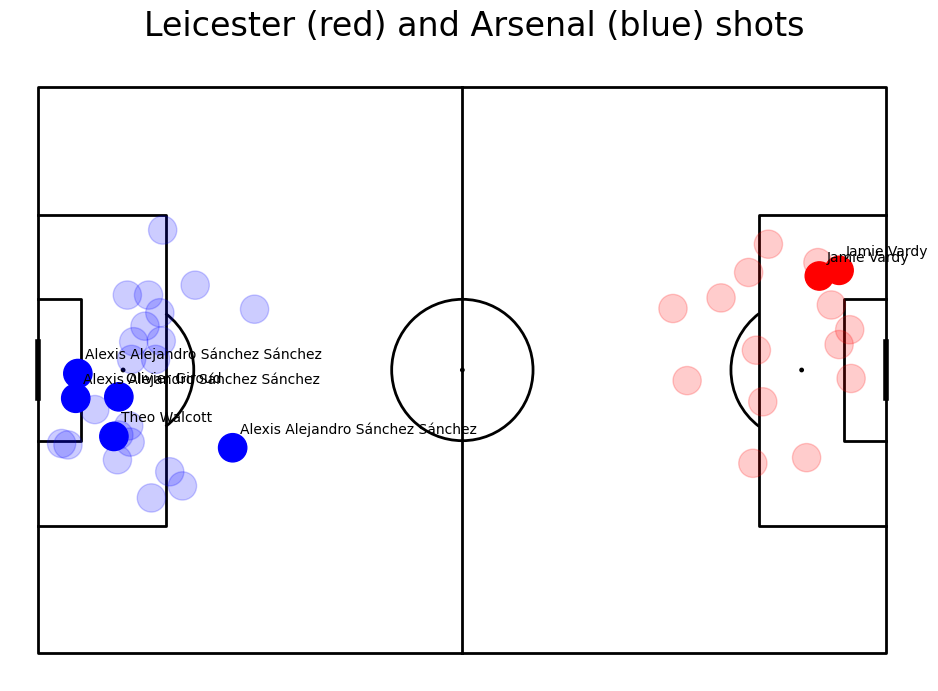

In [12]:
#PLOTTING SHOTS WITH DARKER CIRCLES FOR GOALS
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
#Plot the shots by looping through them.
for i,shot in shots.iterrows():
    #get the information 
    x=shot['x']
    y=shot['y']
    goal=shot['outcome_name']=='Goal'
    team_name=shot['team_name']    
    #set circlesize
    circleSize=2
    #plot England
    if (team_name==team1):
        if goal:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,shot['player_name']) 
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
    #plot Sweden
    else:
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
    ax.add_patch(shotCircle)
#set title
fig.suptitle("Leicester (red) and Arsenal (blue) shots", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

# PASS MAP-(FROM SUMPTER)

In [19]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3754174)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
passes = df.loc[df['type_name'] == 'Pass'].set_index('id')

In [20]:
team1,team2=passes['team_name'].unique()
passes['team_name']

id
36cfdf75-c538-42f2-8f77-815985b9bfc2    Leicester City
cba32dab-8447-487a-9570-92dd84c8dff8    Leicester City
a16b2071-fa2c-453d-a302-9170c2adae75    Leicester City
a4c7c201-357f-4349-a7bb-9a8e78a97722           Arsenal
7cf4588b-9e81-4ea5-be85-ebc897e001d6    Leicester City
                                             ...      
bbaaddc6-3ead-4dcf-bf5a-baeef36ec40f    Leicester City
a38355b5-f9f8-44d3-9162-cac4c83e48dd    Leicester City
c16e211e-e51f-4527-93aa-cd9930a8b944    Leicester City
5bed6b0b-0a16-40db-8709-81f089a985a7    Leicester City
e22866d0-d28f-46ba-9591-835c916ac48e    Leicester City
Name: team_name, Length: 1012, dtype: object

In [15]:
passes['player_name'].unique()

array(['Shinji Okazaki', "N''Golo Kanté", 'Danny Drinkwater',
       'Per Mertesacker', 'Héctor Bellerín Moruno', 'Laurent Koscielny',
       'Alexis Alejandro Sánchez Sánchez', 'Santiago Cazorla González',
       'Ignacio Monreal Eraso', 'Aaron Ramsey', 'Jeffrey Schlupp',
       'Kasper Schmeichel', 'Mesut Özil', 'Wes Morgan', 'Riyad Mahrez',
       'Marc Albrighton', 'Petr Čech', 'Mathieu Flamini',
       'Ritchie De Laet', 'Jamie Vardy', 'Theo Walcott', 'Robert Huth',
       'Mikel Arteta Amatriain', 'Andrew Philip King',
       'José Leonardo Ulloa', 'Andrej Kramarić', 'Olivier Giroud',
       'Alex Oxlade-Chamberlain'], dtype=object)

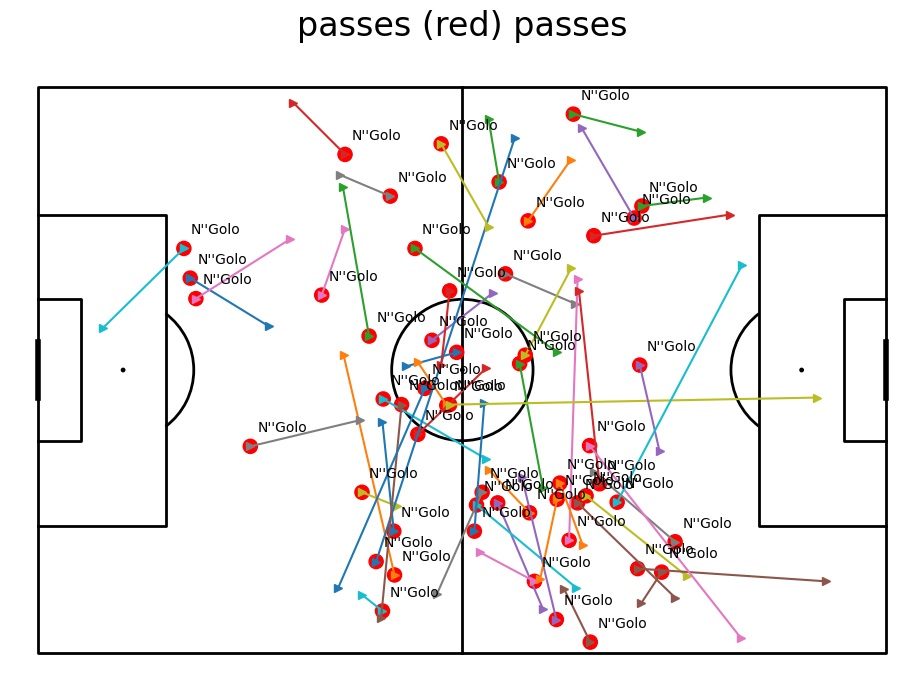

In [21]:
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
prev=0
count=0
posx=[]
posy=[]
#Plot the shots by looping through them.
for i,passes in passes.iterrows():
    #get the information 
    x=passes['x']
    y=passes['y']
    endx=passes['end_x']
    endy=passes['end_y']
    goal=passes['outcome_name']=='Pass'
    team_name=passes['team_name']
    player=passes['player_name']=="N''Golo Kanté"
    #set circlesize
    circleSize=1
    #plot messi
    if (team_name==team1):
        if player:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,passes['player_name'].split()[0])
            ax.add_patch(shotCircle)
            count=count+1
            posx.append(x)
            posy.append(y)
            posx.append(endx)
            posy.append(endy)
    
            
#            plt.plot()
            
            
            
#            plt.arrow(x,y,10,10,head_width=3,head_length=2)
'''
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
 

    #plot England
    else:
        continue
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
 #           plt.arrow(x+1,y-2,5,1)
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
'''


#set title
for i in range(0, len(posx), 2):
    plt.plot(posx[i:i+2], posy[i:i+2], '->')
    
fig.suptitle("passes (red) passes", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

# USING THE CONTENT FROM MADABOUTSPORTS

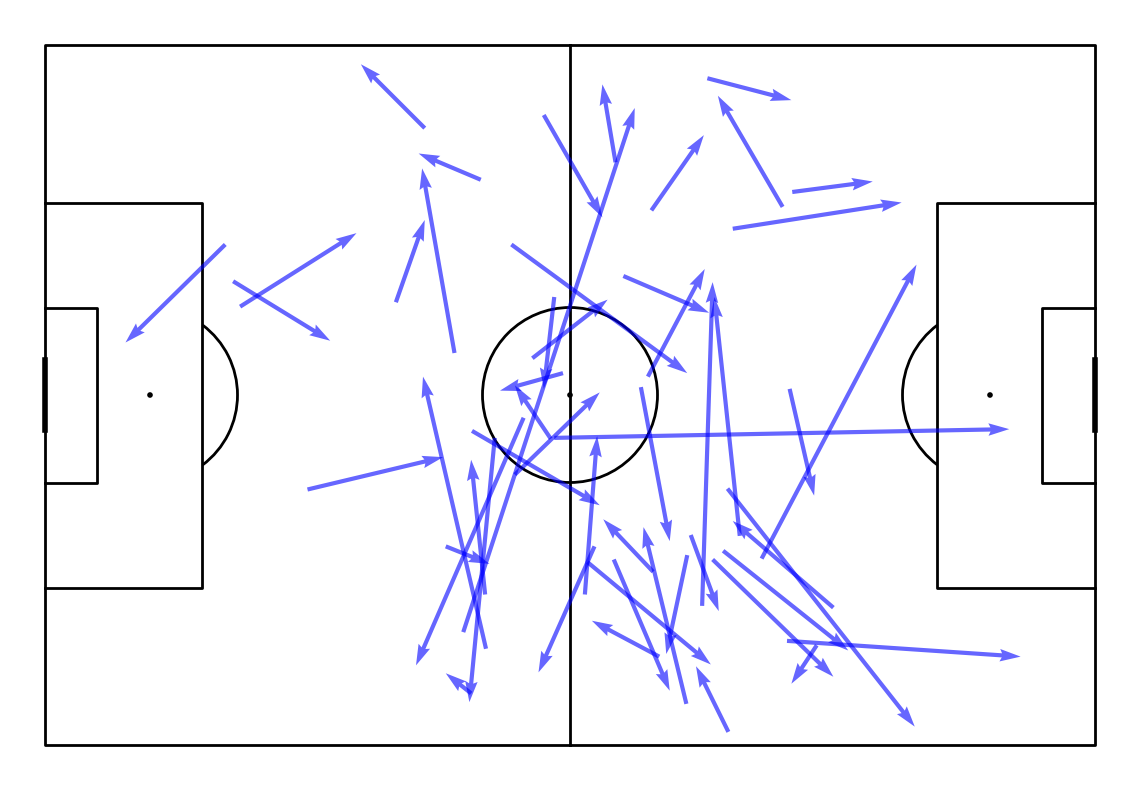

In [22]:
df1=df[df["type_name"]=="Pass"]

df2=df1[df1["team_name"]=="Leicester City"]

df3=df2[df2["player_name"]=="N''Golo Kanté"]

pitch=mplsoccer.Pitch(pitch_type='statsbomb',pitch_color='white',line_color='black')
fig,ax=pitch.draw(figsize=(14,8))
pitch.arrows(df3['x'],df3['y'],df3['end_x'],df3['end_y'],alpha=0.6,width=3,ax=ax,color='blue')
plt.show()

# PASS NETWORKS BLACK BOX CODE

/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_96758/3540882733.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jersey_data.rename(columns={'player_id':'pass_recipient_id'},inplace=True)
/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_96758/3540882733.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jersey_data.rename(columns={'jersey_number':'pass_recipient'},inplace=True)


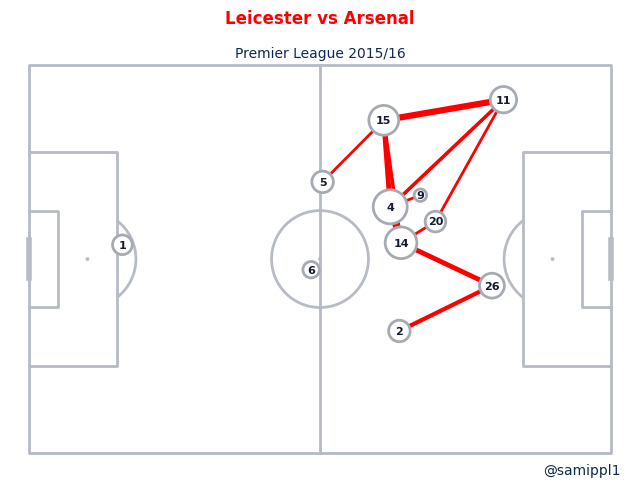

In [24]:
#LOADING DATA

parser= Sbopen()

df, related, freeze, tactics = parser.event(3754174)

#SELECTING TEAM

df = df[df['team_name']=='Leicester City']

#SELECTING ACTION TYPE

passes = df[df['type_name']=='Pass']
filtered = passes[['player_name','x','y','end_x', 'end_y','pass_recipient_name','outcome_id','outcome_name','position_name']]

filtered[filtered['outcome_name'].isnull()]

df_lineup = parser.lineup(3754174)
jersey_data=df_lineup[['player_id','jersey_number']]

df= pd.merge(df,jersey_data,on='player_id')



#player id is the jersey number
df['passer'] = df['jersey_number']
passes = df[df['type_name']=='Pass']
successful = passes[passes['outcome_name'].isnull()]

rec= pd.to_numeric(successful['pass_recipient_id'],downcast='integer')
jersey_data.rename(columns={'player_id':'pass_recipient_id'},inplace=True)
jersey_data.rename(columns={'jersey_number':'pass_recipient'},inplace=True)
successful=pd.merge(df,jersey_data,on='pass_recipient_id')
successful

subs = df[df['type_name']=='Substitution']
subs = subs['minute']
firstSub=subs.min()


#FOR FRANCE SET firstSub into something else

#firstSub=63

successful = successful[successful['minute']<firstSub]

successful

successful.dtypes




successful

df['pass_recipient_id'].unique()

average_locations= successful.groupby('passer').agg({'x':['mean'],'y':['mean','count']})
average_locations.columns = ['x','y','count']

average_locations

pass_between = successful.groupby(['passer','pass_recipient']).id.count().reset_index()
pass_between.rename({'id':'pass_count'},axis='columns',inplace=True)
pass_between

pass_between= pass_between.merge(average_locations,left_on='passer',right_index=True)
pass_between


pass_between= pass_between.merge(average_locations,left_on='pass_recipient',right_index=True,suffixes=['','_end'])
pass_between

pass_between =pass_between[pass_between['pass_count']>3]
pass_between.drop_duplicates()
pass_between

average_locations['count'].values
pass_between['pass_count'].values

pass_between

# def create_arrow(row):
#     return mpatches.Arrow(1.2*row['x'], 0.8*row['y'], 1.2*row['x_end'], 0.8*row['y_end'], width=row['pass_count']*0.1, color='red')

pitch = Pitch(pitch_color='#FFFFFF', line_color='#B6BBC4')
# Set the figure size
fig, ax = pitch.draw(figsize=(8, 6), constrained_layout=True, tight_layout=False)

# Set the face color of the figure
fig.set_facecolor('#FFFFFF')

# Draw arrows and nodes
# arrows = pitch.arrows(1.2 * pass_between.x, 0.8 * pass_between.y, 1.2 * pass_between.x_end, 0.8 * pass_between.y_end, ax=ax,color='red', alpha=0.4,width=3)
pass_lines = pitch.lines(1.2*pass_between.x, 0.8*pass_between.y, 1.2*pass_between.x_end, 0.8*pass_between.y_end, lw=pass_between.pass_count*0.5,color='red', zorder=1, ax=ax)
                 
nodes = pitch.scatter(1.2 * average_locations.x, 0.8 * average_locations.y, s=20*average_locations['count'].values, color='white', edgecolors='#a6aab3', linewidth=2, alpha=1, zorder=1, ax=ax)

                 
# Annotate average_locations
for index, row in average_locations.iterrows():
    pitch.annotate(index, xy=(1.2 * row.x, 0.8 * row.y), c='#161A30',fontweight='bold', va='center', ha='center', size=8, ax=ax)

# Add the endnote
ax.text(114, 85, '@samippl1', color='#0E2954', va='bottom', ha='center', fontsize=10)

# Add the title
ax.set_title('Leicester vs Arsenal', color='red', va='center', ha='center', fontsize=12,fontweight='bold',pad=20,loc='center')
ax.annotate('Premier League 2015/16', xy=(0.5, 1), xytext=(0, 0),
             xycoords='axes fraction', textcoords='offset points',
             fontsize=10, color='#0E2954', va='top', ha='center')


plt.show()

# MODIFIED ONE WITH PLAYER NAMES AND COLOUR CODES FOR POSTIONS

In [82]:
#ARGENTINA MATCH DIRECTORY 2022
#AUSTRALIA-3869151
#FRANCE-3869685
#MEXICO-3857289
#CROATIA-3869519
#SAUDI-3857300
#NETHERLANDS-3869321
#POLAND-3857264

In [25]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3754174)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
df = df[df['team_name']=='Leicester City']

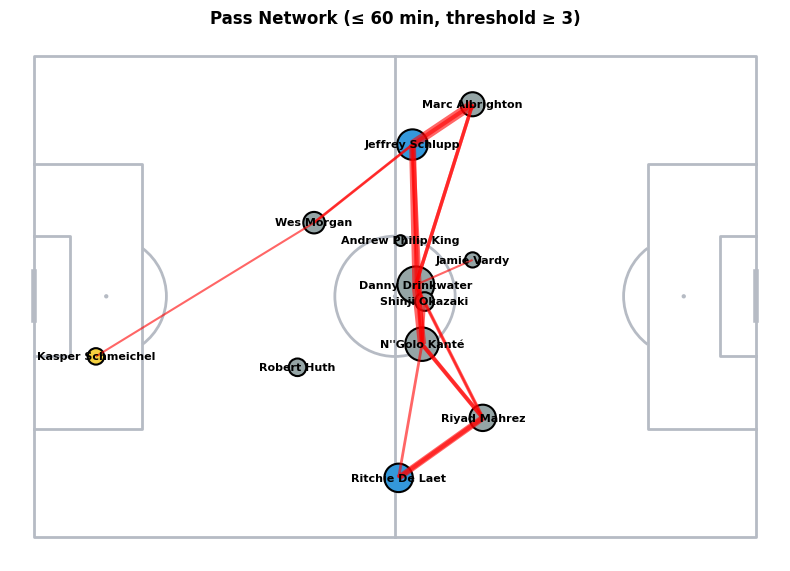

In [26]:
# =========================
# BUILD BASE PASS DATA
# =========================

base_passes = df[
    (df['type_name'] == 'Pass') &
    (df['outcome_name'].isnull()) &
    (df['player_name'].notna()) &
    (df['pass_recipient_name'].notna())
].copy()

# =========================
# PLOT FUNCTION
# =========================

def plot_pass_network(base_passes, threshold=1, max_minute=None):

    # Time filter
    if max_minute is not None:
        passes = base_passes[base_passes['minute'] <= max_minute]
    else:
        passes = base_passes.copy()

    # Average locations + position
    average_locations = passes.groupby('player_name').agg(
        x=('x', 'mean'),
        y=('y', 'mean'),
        count=('x', 'count'),
        position_name=('position_name', 'first')
    ).reset_index()

    # Position → color map
    position_colors = {
        'Goalkeeper': '#F4D03F',
        'Centre Back': '#3498DB',
        'Left Back': '#3498DB',
        'Right Back': '#3498DB',
        'Defensive Midfield': '#2ECC71',
        'Central Midfield': '#2ECC71',
        'Attacking Midfield': '#58D68D',
        'Left Wing': '#E74C3C',
        'Right Wing': '#E74C3C',
        'Centre Forward': '#C0392B'
    }

    average_locations['color'] = (
        average_locations['position_name']
        .map(position_colors)
        .fillna('#95A5A6')
    )

    # Pass counts
    pass_between = (
        passes
        .groupby(['player_name', 'pass_recipient_name'])
        .size()
        .reset_index(name='pass_count')
    )

    # Threshold filter
    pass_between = pass_between[pass_between['pass_count'] >= threshold]

    # Merge locations
    pass_between = pass_between.merge(
        average_locations.set_index('player_name'),
        left_on='player_name',
        right_index=True
    )

    pass_between = pass_between.merge(
        average_locations.set_index('player_name'),
        left_on='pass_recipient_name',
        right_index=True,
        suffixes=['', '_end']
    )

    # =========================
    # PLOT
    # =========================

    pitch = Pitch(pitch_color='#FFFFFF', line_color='#B6BBC4')
    fig, ax = pitch.draw(figsize=(8, 6))
    fig.set_facecolor('#FFFFFF')

    # Pass lines
    pitch.lines(
        pass_between.x,
        pass_between.y,
        pass_between.x_end,
        pass_between.y_end,
        lw=pass_between.pass_count * 0.5,
        color='red',
        alpha=0.6,
        ax=ax
    )

    # Player nodes
    pitch.scatter(
        average_locations.x,
        average_locations.y,
        s=20 * average_locations['count'],
        c=average_locations['color'],
        edgecolors='black',
        linewidth=1.5,
        ax=ax
    )

    # Labels
    for _, row in average_locations.iterrows():
        pitch.annotate(
            row['player_name'],
            (row.x, row.y),
            ha='center',
            va='center',
            fontsize=8,
            fontweight='bold',
            ax=ax
        )

    title = f'Pass Network (≤ {max_minute} min, threshold ≥ {threshold})' if max_minute else f'Pass Network (threshold ≥ {threshold})'
    ax.set_title(title, fontsize=12, fontweight='bold')

    plt.show()

# =========================
# USAGE
# =========================

plot_pass_network(base_passes, threshold=3, max_minute=60)



# TO SEE THE NETWORK QUANTITIES

In [27]:
pass_df = (
    df[
        (df['type_name'] == 'Pass') &
        (df['outcome_name'].isnull()) &
        (df['player_name'].notna()) &
        (df['pass_recipient_name'].notna())
    ]
    .groupby(['player_name', 'pass_recipient_name'])
    .size()
    .reset_index(name='pass_count')
    .sort_values('pass_count', ascending=False)
)

pass_df = pass_df.rename(columns={
    'player_name': 'passer',
    'pass_recipient_name': 'receiver'
})


In [28]:



# Example pass dataframe
# Replace this with your actual dataframe

# Create a directed graph
G = nx.DiGraph()

# Add edges with weights
for _, row in pass_df.iterrows():
    G.add_edge(
        row['passer'],
        row['receiver'],
        weight=row['pass_count']
    )

# Check nodes and edges
#print("Nodes:", G.nodes())
print("Edges with weights:", G.edges(data=True))


Edges with weights: [("N''Golo Kanté", 'Danny Drinkwater', {'weight': 14}), ("N''Golo Kanté", 'Jeffrey Schlupp', {'weight': 8}), ("N''Golo Kanté", 'Riyad Mahrez', {'weight': 7}), ("N''Golo Kanté", 'Ritchie De Laet', {'weight': 5}), ("N''Golo Kanté", 'Andrew Philip King', {'weight': 3}), ("N''Golo Kanté", 'José Leonardo Ulloa', {'weight': 2}), ("N''Golo Kanté", 'Jamie Vardy', {'weight': 1}), ("N''Golo Kanté", 'Kasper Schmeichel', {'weight': 1}), ("N''Golo Kanté", 'Shinji Okazaki', {'weight': 1}), ('Danny Drinkwater', 'Jeffrey Schlupp', {'weight': 12}), ('Danny Drinkwater', 'Riyad Mahrez', {'weight': 8}), ('Danny Drinkwater', 'Andrew Philip King', {'weight': 5}), ('Danny Drinkwater', 'Marc Albrighton', {'weight': 5}), ('Danny Drinkwater', 'Jamie Vardy', {'weight': 4}), ('Danny Drinkwater', 'Ritchie De Laet', {'weight': 4}), ('Danny Drinkwater', "N''Golo Kanté", {'weight': 4}), ('Danny Drinkwater', 'Shinji Okazaki', {'weight': 2}), ('Danny Drinkwater', 'Wes Morgan', {'weight': 2}), ('Dann

In [29]:
eig_centrality = nx.eigenvector_centrality(
    G,
    max_iter=1000,   # Increase iterations if it doesn't converge
    weight='weight'  # Use edge weight (e.g., number of passes)
)
bet_centrality=nx.betweenness_centrality(G)
clo_centrality=nx.closeness_centrality(G)
# Convert to a DataFrame for easy viewing

cent_df = pd.DataFrame()
cent_df['player name'] = eig_centrality.keys()  
cent_df['eigenvector_centrality'] = eig_centrality.values()
cent_df['betweenness_centrality']=bet_centrality.values()
cent_df['closeness_centrality']=clo_centrality.values()
cent_df = cent_df.sort_values('betweenness_centrality', ascending=False)


'''


'''
(cent_df)




,player name,eigenvector_centrality,betweenness_centrality,closeness_centrality
1,Danny Drinkwater,0.434655,0.064708,0.928571
5,Riyad Mahrez,0.412262,0.064530,0.866667
0,N''Golo Kanté,0.326092,0.050712,0.866667
4,Ritchie De Laet,0.286137,0.048771,0.722222
2,Jeffrey Schlupp,0.411716,0.045459,0.722222
7,Andrew Philip King,0.237108,0.042486,0.866667
12,Jamie Vardy,0.215247,0.031642,0.928571
8,Robert Huth,0.114936,0.020139,0.684211
6,Wes Morgan,0.140967,0.017058,0.722222
3,Marc Albrighton,0.321695,0.012233,0.650000


In [30]:
cent_df

,player name,eigenvector_centrality,betweenness_centrality,closeness_centrality
1,Danny Drinkwater,0.434655,0.064708,0.928571
5,Riyad Mahrez,0.412262,0.064530,0.866667
0,N''Golo Kanté,0.326092,0.050712,0.866667
4,Ritchie De Laet,0.286137,0.048771,0.722222
2,Jeffrey Schlupp,0.411716,0.045459,0.722222
7,Andrew Philip King,0.237108,0.042486,0.866667
12,Jamie Vardy,0.215247,0.031642,0.928571
8,Robert Huth,0.114936,0.020139,0.684211
6,Wes Morgan,0.140967,0.017058,0.722222
3,Marc Albrighton,0.321695,0.012233,0.650000


# ATTEMPT TO FIND PASSING TRIANGLE

In [91]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3754174)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
passes = df.loc[df['type_name'] == 'Pass'].set_index('id')

In [111]:

# keep only completed passes with a known recipient
passes_clean = passes[
    passes['outcome_name'].isna() &
    passes['pass_recipient_id'].notna()
].copy()

passes_clean = passes_clean.sort_values('timestamp').reset_index(drop=True)

# integer ids are easier to work with
passes_clean['player_id'] = passes_clean['player_id'].astype(int)
passes_clean['pass_recipient_id'] = passes_clean['pass_recipient_id'].astype(int)

print(passes_clean[['timestamp', 'player_id', 'pass_recipient_id']].head(10))
print(f"\n{len(passes_clean)} completed passes, {passes_clean['player_id'].nunique()} unique passers")

         timestamp  player_id  pass_recipient_id
0  00:00:00.082000       3810               3961
1  00:00:00.419000       3961               3662
2  00:00:00.876000       3496              42703
3  00:00:02.338000      42703              11386
4  00:00:03.935000      11386               3475
5  00:00:06.998000       3961               3520
6  00:00:14.945000       3517              11386
7  00:00:17.408000      11386               3475
8  00:00:20.365000       3511               3475
9  00:00:20.748000       3475               3511

797 completed passes, 28 unique passers


In [112]:
TEAM = 'Arsenal'  # replace with the exact name from the print above

passes_team = passes_clean[passes_clean['team_name'] == TEAM].copy()
print(f"{len(passes_team)} passes for {TEAM}")
passes_clean=passes_team

479 passes for Arsenal


In [113]:
passes_clean['timestamp_sec'] = passes_clean['timestamp'].apply(
    lambda t: t.hour * 3600 + t.minute * 60 + t.second + t.microsecond / 1e6
)

In [114]:
passes_clean = passes_clean.rename(columns={'pass_recipient_id': 'recipient_id'})
passes_clean = passes_clean.dropna(subset=['timestamp_sec', 'player_id', 'recipient_id'])
passes_clean['timestamp_sec'] = passes_clean['timestamp_sec'].astype(float)
passes_clean['player_id'] = passes_clean['player_id'].astype(int)
passes_clean['recipient_id'] = passes_clean['recipient_id'].astype(int)
passes_clean = passes_clean.sort_values('timestamp_sec').reset_index(drop=True)

print(passes_clean[['timestamp_sec', 'player_id', 'recipient_id']].head(10))

   timestamp_sec  player_id  recipient_id
0          0.876       3496         42703
1          2.338      42703         11386
2          3.935      11386          3475
3         14.945       3517         11386
4         17.408      11386          3475
5         20.365       3511          3475
6         20.748       3475          3511
7         24.160       3475          3394
8         28.789       3394          3475
9         31.699       3475          3511


In [115]:
period_offsets = {1: 0, 2: 45*60, 3: 90*60, 4: 105*60}
passes_clean['timestamp_sec'] += passes_clean['period'].map(period_offsets)
passes_clean = passes_clean.sort_values('timestamp_sec').reset_index(drop=True)

In [116]:
from collections import Counter
def extract_triplets(df, time_window=10):
    triplets = []
    arr = df[['timestamp_sec', 'player_id', 'recipient_id']].values

    for i in range(len(arr)):
        t1, sender, receiver = arr[i]
        for j in range(i + 1, len(arr)):
            t2, sender2, receiver2 = arr[j]
            if t2 - t1 > time_window:
                break
            if sender2 == receiver:
                kind = 'return' if receiver2 == sender else 'open'
                triplets.append((int(sender), int(receiver), int(receiver2), kind))
                break
    return triplets

observed_triplets = extract_triplets(passes_clean, time_window=10)

# split by kind
open_triplets   = [(a, b, c) for a, b, c, k in observed_triplets if k == 'open']
return_triplets = [(a, b, c) for a, b, c, k in observed_triplets if k == 'return']

print(f"Open sequences  A→B→C (all distinct): {len(open_triplets)}")
print(f"Return sequences A→B→A (give-and-go): {len(return_triplets)}")

Open sequences  A→B→C (all distinct): 302
Return sequences A→B→A (give-and-go): 62


In [117]:
observed_counts_open   = Counter(open_triplets)
observed_counts_return = Counter(return_triplets)

print("\nTop open combinations:")
for t, n in observed_counts_open.most_common(10):
    a, b, c = t
    print(f"  {id_to_name.get(a,'?')} → {id_to_name.get(b,'?')} → {id_to_name.get(c,'?')}  (n={n})")

print("\nTop give-and-go pairs:")
for t, n in observed_counts_return.most_common(10):
    a, b, _ = t   # c == a
    print(f"  {id_to_name.get(a,'?')} ↔ {id_to_name.get(b,'?')}  (n={n})")


Top open combinations:
  ? → ? → ?  (n=6)
  ? → ? → ?  (n=6)
  ? → ? → ?  (n=6)
  ? → ? → ?  (n=5)
  ? → ? → ?  (n=4)
  ? → ? → ?  (n=4)
  ? → ? → ?  (n=3)
  ? → ? → ?  (n=3)
  ? → ? → ?  (n=3)
  ? → ? → ?  (n=3)

Top give-and-go pairs:
  ? ↔ ?  (n=4)
  ? ↔ ?  (n=3)
  ? ↔ ?  (n=3)
  ? ↔ ?  (n=3)
  ? ↔ ?  (n=3)
  ? ↔ ?  (n=2)
  ? ↔ ?  (n=2)
  ? ↔ ?  (n=2)
  ? ↔ ?  (n=2)
  ? ↔ ?  (n=2)


In [118]:
def validate_typed_triplets(df, triplet_list, n_surrogates=500, alpha=0.05):
    observed_counts = Counter(triplet_list)
    candidate_triplets = list(observed_counts.keys())
    if not candidate_triplets:
        print("No triplets to validate.")
        return [], observed_counts

    print(f"{len(candidate_triplets)} candidates, {n_surrogates} surrogates...")
    null_counts = {t: [] for t in candidate_triplets}

    for s in range(n_surrogates):
        surr_all = extract_triplets(shuffle_passes(df), time_window=10)
        # filter to same kind
        kind = 'return' if candidate_triplets[0][2] == candidate_triplets[0][0] else 'open'
        surr_filtered = [(a,b,c) for a,b,c,k in surr_all if k == kind]
        surr_counts = Counter(surr_filtered)
        for t in candidate_triplets:
            null_counts[t].append(surr_counts.get(t, 0))
        if (s+1) % 100 == 0:
            print(f"  {s+1}/{n_surrogates}")

    p_values = [np.mean(np.array(null_counts[t]) >= observed_counts[t])
                for t in candidate_triplets]
    reject, _, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')
    significant = [t for t, r in zip(candidate_triplets, reject) if r]
    print(f"  → {len(significant)} significant")
    return significant, observed_counts

print("=== Open sequences ===")
sig_open, counts_open = validate_typed_triplets(passes_clean, open_triplets)

print("\n=== Return / give-and-go ===")
sig_return, counts_return = validate_typed_triplets(passes_clean, return_triplets)

=== Open sequences ===
213 candidates, 500 surrogates...
  100/500
  200/500
  300/500
  400/500
  500/500
  → 87 significant

=== Return / give-and-go ===
38 candidates, 500 surrogates...
  100/500
  200/500
  300/500
  400/500
  500/500
  → 17 significant


In [119]:
# avg_pos: passer positions
passer_pos = passes_clean.groupby('player_id')[['x', 'y']].mean()

# recipient positions from end_x, end_y
recipient_pos = passes_clean.groupby('recipient_id')[['end_x', 'end_y']].mean()
recipient_pos.columns = ['x', 'y']

# merge: prefer passer position if available, fill in from recipient otherwise
avg_pos = passer_pos.combine_first(recipient_pos)

print(avg_pos.head())
print(f"\n{len(avg_pos)} players with position data")

                   x          y
player_id                      
3385       79.254054  15.583784
3394       44.733333  27.664706
3461        9.040000  38.070000
3475       40.475410  59.465574
3496       73.922449  37.371429

14 players with position data


In [120]:
id_to_name = {}
for _, row in passes_clean.iterrows():
    id_to_name[int(row['player_id'])] = row['player_name']
    if pd.notna(row['recipient_id']):
        id_to_name[int(row['recipient_id'])] = row['pass_recipient_name']

In [121]:
# ── 2. count closed triplets A→B→A ──────────────────────────────────────────
# sig_return already has validated (A, B, A) tuples — use counts_return
# build edge weights: for a give-and-go (A,B,A) the pair is (A,B)
pair_counts = Counter()
for (a, b, c), n in counts_return.items():
    if (a, b, c) in [t for t in sig_return]:   # only significant ones
        pair = tuple(sorted([a, b]))
        pair_counts[pair] += n

# also collect closed triangles from significant open triplets:
# a closed triangle exists when (A,B,C) and (B,C,A) and (C,A,B) are all significant
# simpler: just look for any cycle A→B→C where we also have A→C or C→A in sig_open
sig_open_set = set(sig_open)

triangle_edges = Counter()   # edge (u,v) sorted → total weight
triangles_found = []

for (a, b, c) in sig_open:
    # check if the triangle closes: is (b,c,a) or (c,a,b) also significant?
    if (b, c, a) in sig_open_set or (c, a, b) in sig_open_set:
        for u, v in [(a,b),(b,c),(a,c)]:
            triangle_edges[tuple(sorted([u,v]))] += counts_open[(a,b,c)]
        triangles_found.append((a,b,c))

# merge give-and-go pairs into triangle_edges too
for pair, n in pair_counts.items():
    triangle_edges[pair] += n

print(f"Closed triangles from open triplets: {len(triangles_found)}")
print(f"Give-and-go pairs in edge set: {len(pair_counts)}")
print(f"Total unique edges to draw: {len(triangle_edges)}")

Closed triangles from open triplets: 28
Give-and-go pairs in edge set: 14
Total unique edges to draw: 33


In [122]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import numpy as np

# ── collect all unique closed triangles as frozensets ───────────────────────
# from open triplets: (A,B,C) closes if (B,C,A) or (C,A,B) also significant
sig_open_set = set(sig_open)

closed_triangles = []  # list of (frozenset{a,b,c}, total_weight)
seen = set()

for (a, b, c) in sig_open:
    tri = frozenset([a, b, c])
    if tri in seen:
        continue
    if (b, c, a) in sig_open_set or (c, a, b) in sig_open_set:
        w = (counts_open.get((a,b,c), 0) +
             counts_open.get((b,c,a), 0) +
             counts_open.get((c,a,b), 0))
        closed_triangles.append((tri, w))
        seen.add(tri)

# also add give-and-go pairs as degenerate "triangles" (just edges) if you want
# — skip for now, only draw full triangles

print(f"{len(closed_triangles)} closed triangles found")

# ── assign one colour per triangle ──────────────────────────────────────────
cmap = cm.get_cmap('tab20', max(len(closed_triangles), 1))
tri_colors = [cmap(i) for i in range(len(closed_triangles))]

14 closed triangles found


/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_96758/507277328.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('tab20', max(len(closed_triangles), 1))


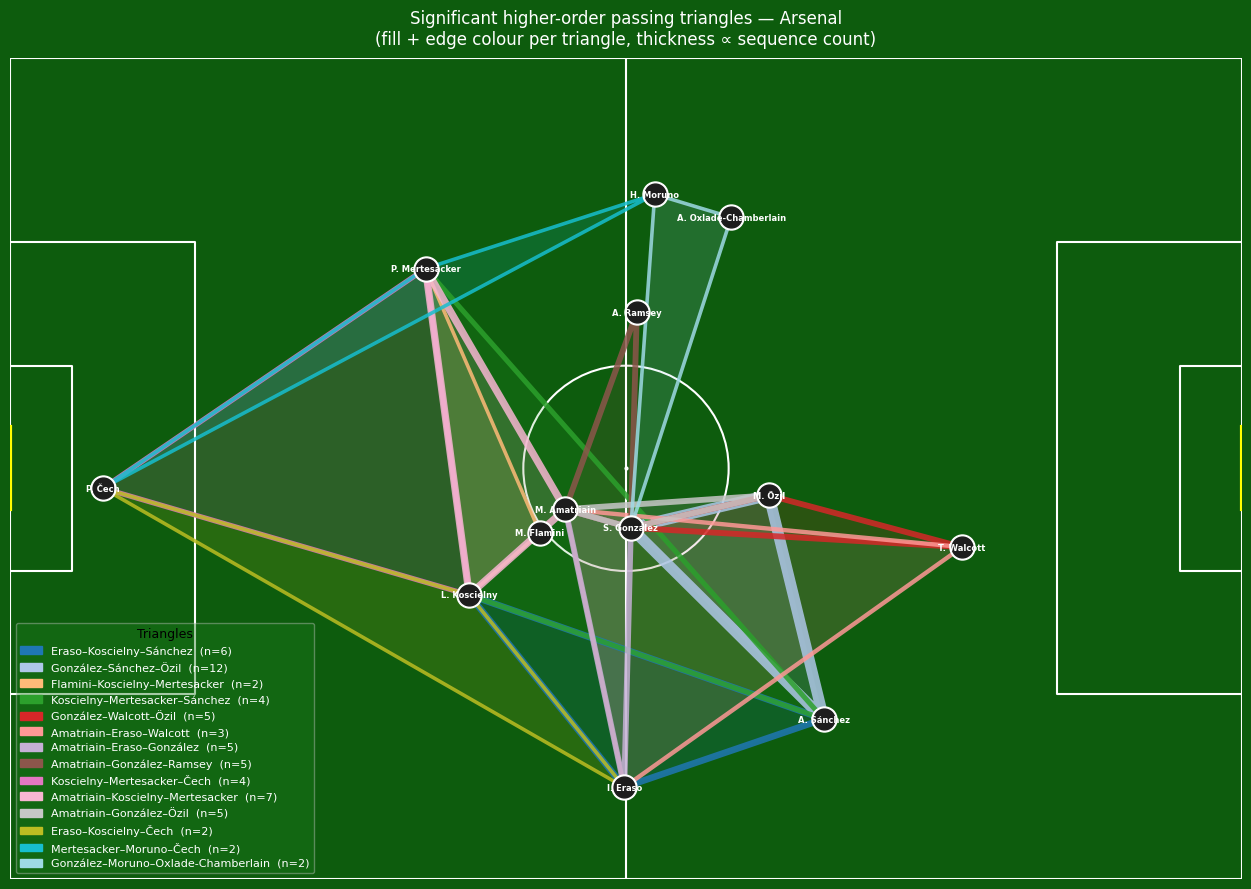

In [123]:
fig, ax = plt.subplots(figsize=(14, 9))
draw_pitch(ax)

legend_handles = []

for idx, ((tri, w), color) in enumerate(zip(closed_triangles, tri_colors)):
    players = list(tri)
    # need positions for all three
    if any(p not in avg_pos.index or avg_pos.loc[p].isna().any() for p in players):
        continue

    coords = [(avg_pos.loc[p, 'x'], avg_pos.loc[p, 'y']) for p in players]
    xs = [c[0] for c in coords] + [coords[0][0]]
    ys = [c[1] for c in coords] + [coords[0][1]]

    # edge thickness proportional to weight
    max_w = max(t[1] for t in closed_triangles)
    lw = 1.5 + 6.5 * (w / max_w)

    # filled triangle (low alpha)
    triangle = plt.Polygon(coords, closed=True,
                           facecolor=color, alpha=0.15, zorder=1)
    ax.add_patch(triangle)

    # triangle edges
    ax.plot(xs, ys, color=color, lw=lw, alpha=0.85,
            solid_capstyle='round', zorder=2)

    # legend entry
    names = [id_to_name.get(p, str(p)).split()[-1] for p in players]
    label = f"{'–'.join(sorted(names))}  (n={w})"
    legend_handles.append(mpatches.Patch(color=color, label=label))

# ── nodes ────────────────────────────────────────────────────────────────────
nodes_to_draw = set()
for tri, _ in closed_triangles:
    nodes_to_draw.update(tri)

for pid in nodes_to_draw:
    if pid not in avg_pos.index or avg_pos.loc[pid].isna().any():
        continue
    x, y = avg_pos.loc[pid, 'x'], avg_pos.loc[pid, 'y']
    name  = id_to_name.get(pid, str(pid))
    parts = name.split()
    short = f"{parts[0][0]}. {parts[-1]}" if len(parts) > 1 else name

    ax.plot(x, y, 'o', color='white', ms=18, zorder=3)
    ax.plot(x, y, 'o', color='#1d1d1d', ms=15, zorder=4)
    ax.text(x, y, short, ha='center', va='center',
            fontsize=6, color='white', fontweight='bold', zorder=5)

# ── legend ───────────────────────────────────────────────────────────────────
ax.legend(handles=legend_handles, loc='lower left',
          fontsize=8, framealpha=0.4,
          labelcolor='white', facecolor='#1a7a1a',
          title='Triangles', title_fontsize=9)

ax.set_title(f'Significant higher-order passing triangles — {TEAM}\n'
             f'(fill + edge colour per triangle, thickness ∝ sequence count)',
             color='white', fontsize=12, pad=10)
fig.patch.set_facecolor('#0d5c0d')
plt.tight_layout()
plt.show()